# Build and Query a Feature Store for ML Training and Serving

In [136]:
import pandas as pd
import numpy as np
import os
from feast import FeatureStore
from datetime import datetime
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report
import warnings
warnings.filterwarnings("ignore")

## EDA

In [137]:
df = pd.read_csv ("/kaggle/input/datasets/ealaxi/paysim1/PS_20174392719_1491204439457_log.csv")

In [138]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [139]:
df.shape

(6362620, 11)

In [140]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [141]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [142]:
df["type"].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [143]:
df["isFraud"].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [144]:
df["step"].min(), df["step"].max()

(1, 743)

## Entity Selection

In [145]:
counts = df["nameOrig"].value_counts()
print("Number of unique customers:", len(counts))
print("Customer with more than 1 transaction:", (counts > 1).sum())
print("Maximum number of transactions:", counts.max())

Number of unique customers: 6353307
Customer with more than 1 transaction: 9298
Maximum number of transactions: 3


In [146]:
dest_counts = df["nameDest"].value_counts()
print("Unique field count:", len(dest_counts))
print("Field with more than 1 transaction:", (dest_counts > 1).sum())
print("Field with more than 10 transactions:", (dest_counts > 10).sum())
print("Maksimum:", dest_counts.max())

Unique field count: 2722362
Field with more than 1 transaction: 459658
Field with more than 10 transactions: 130286
Maksimum: 113


In this project, we are building a feature store for fraud detection. Features should answer the question: "What has this entity done in the past?" For this to work, the tracked entity needs to appear multiple times in the data.

An entity is the primary object that features belong to - essentially the answer to "Whose history are we tracking?" The feature store binds each feature to an entity key (e.g., account ID). The entity itself is an identifier, not a calculation.

"nameDest" (the recipient account) was selected as the entity because:

- Sender accounts almost always appear only once (with a maximum of 3 transactions). History-based features (such as count or average amount over the last 24 hours) would always be empty or 0 for them.
- Recipient accounts recur and possess a rich transaction history.
- Fraud logic: Fraudsters often consolidate funds into a few specific accounts. Features like "how many transactions has this account received recently?" and "what is the average transaction amount?" can effectively expose this behavior.

---
Bu layihədə fraud aşkarlama üçün feature store qururuq. Feature-lər "bu obyekt keçmişdə nə edib?" sualına cavab verməlidir. Bunun üçün izlədiyimiz obyektin datada "bir neçə dəfə görünməsi" lazımdır.

Entity feature-lərin aid olduğu əsas obyektdir, yəni "kimin tarixçəsini izləyirik?" sualının cavabı. Feature store hər feature-i bir entity açarı ilə bağlayır (məsələn, hesab ID-si). Entity-nin özü hesablama deyil, identifikatordur.

Seçim,"nameDest" (pulu alan hesab) oldu. Çünki, 

- Göndərənlərin demək olar hamısı yalnız bir dəfə görünür (maksimum 3 əməliyyat). Tarixçəyə əsaslanan feature-lər (son 24 saatda say, orta məbləğ) onlar üçün həmişə boş və ya 0 olardı.
- Alan hesablar isə təkrarlanır və zəngin tarixçəyə malikdir.
- Fraud məntiqi: fırıldaqçılar pulu çox vaxt bir neçə hesaba toplayır. "Bu hesaba son müddətdə neçə əməliyyat gəlib və orta məbləğ nə qədərdir" feature-ləri belə davranışı göstərə bilər.

## Time conversion

In [147]:
base = pd.Timestamp("2025-01-01")
df["event_timestamp"] = base + pd.to_timedelta(df["step"], unit="h")

In [148]:
df[["step", "event_timestamp"]].head()
df["event_timestamp"].min(), df["event_timestamp"].max()

(Timestamp('2025-01-01 01:00:00'), Timestamp('2025-01-31 23:00:00'))

##  Fraud distribution

In [149]:
# Which transaction type contains fraud?
fraud_by_type = df.groupby("type")["isFraud"].agg(["count", "sum", "mean"])
fraud_by_type.columns = ["total_number", "number_of_frauds", "ratio_of_frauds"]
print(fraud_by_type)

          total_number  number_of_frauds  ratio_of_frauds
type                                                     
CASH_IN        1399284                 0         0.000000
CASH_OUT       2237500              4116         0.001840
DEBIT            41432                 0         0.000000
PAYMENT        2151495                 0         0.000000
TRANSFER        532909              4097         0.007688


In [150]:
# Which account type is fraud directed to?
df["dest_prefix"] = df["nameDest"].str[0]
fraud_by_dest = df.groupby("dest_prefix")["isFraud"].agg(["count", "sum", "mean"])
fraud_by_dest.columns = ["total_number", "number_of_frauds", "ratio_of_frauds"]
print(fraud_by_dest)

             total_number  number_of_frauds  ratio_of_frauds
dest_prefix                                                 
C                 4211125              8213          0.00195
M                 2151495                 0          0.00000


3 facts we have measured from the data so far:

1. Fraud occurs only in TRANSFER and CASH_OUT (it is 0 in the other 3 transaction types).
2. Fraud is directed only to C (customer) accounts (it is 0 for M accounts).
3. M (merchant) accounts only receive PAYMENT, and there is no fraud in PAYMENT transactions.

These findings are mutually reinforcing: M accounts = PAYMENT = fraud-free zone.

---
İndiyə qədər datadan ölçdüyümüz 3 fakt:

1. Fırıldaq yalnız TRANSFER və CASH_OUT-dadır (digər 3 növdə 0).
2. Fırıldaq yalnız C (adi hesab) hesablarına gedir (M-də 0).
3. M (satıcı hesabı) hesabları yalnız PAYMENT alır, PAYMENT-də isə fırıldaq yoxdur.

Bunlar bir-birini təsdiqləyir: M hesabları = PAYMENT = fırıldaqsız zona.

In [151]:
c_df = df[df["dest_prefix"] == "C"]

fraud_accounts = c_df[c_df["isFraud"] == 1]["nameDest"].unique()
print("Number of accounts that received fraud:", len(fraud_accounts))

counts_c = c_df["nameDest"].value_counts()
print("Number of C accounts:", len(counts_c))
print("Account C with 5+ transactions:", (counts_c >= 5).sum())

Number of accounts that received fraud: 8169
Number of C accounts: 571961
Account C with 5+ transactions: 280200


In [152]:
fraud_counts = counts_c[counts_c.index.isin(fraud_accounts)]
print(fraud_counts.describe())

count    8169.000000
mean        8.036235
std         9.811278
min         1.000000
25%         1.000000
50%         4.000000
75%        11.000000
max        89.000000
Name: count, dtype: float64


There are 571,961 "C" accounts in the dataset, 280,200 of which have at least 5 transactions. A total of 8,213 fraudulent transactions were directed to 8,169 distinct accounts, and half of these target accounts have 4 or fewer transactions (median: 4, maximum: 89). If we had applied a "5+ transactions" filter, we would have lost approximately half of the fraudulent accounts. Therefore, we retained all fraud-recipient accounts regardless of their transaction count, while randomly sampling normal accounts from those with 5+ transactions.

---
Datada 571 961 "C" hesabı var, onlardan 280 200-ünün ən azı 5 əməliyyatı var. 8 213 fırıldaq əməliyyatı 8 169 fərqli hesaba gedib və bu hesabların yarısında 4 və ya az əməliyyat var (median 4, maksimum 89). Əgər "5+ əməliyyat" süzgəci tətbiq etsəydik, fırıldaq hesablarının təxminən yarısını itirərdik. Buna görə fırıldaq alan bütün hesabları əməliyyat sayından asılı olmayaraq saxladıq, normal hesabları isə 5+ əməliyyatı olanlardan təsadüfi seçdik.

## Subsetting the Data ( df_small )

In [153]:
# 1. List of accounts with fraudulent logins
fraud_set = set(fraud_accounts)

# 2. Normal accounts: those with 5+ transactions and no fraud
normal_pool = counts_c[(counts_c >= 5) & (~counts_c.index.isin(fraud_set))].index

# 3. We randomly select 12,000 accounts from normal accounts
rng = np.random.default_rng(42)
normal_sample = rng.choice(normal_pool, size=12000, replace=False)

# 4. We combine two groups:fraud + normal sample
selected = fraud_set.union(set(normal_sample))

# 5. We save all rows of selected accounts
df_small = c_df[c_df["nameDest"].isin(selected)].copy()

print("Selected account number:", len(selected))
print("df_small number of lines:", len(df_small))
print("Fraud line number", df_small["isFraud"].sum())

Selected account number: 20169
df_small number of lines: 218922
Fraud line number 8213


In [154]:
print(df_small.columns.tolist())
df_small.head()

['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'event_timestamp', 'dest_prefix']


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,event_timestamp,dest_prefix
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0,2025-01-01 01:00:00,C
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.00,0.00,1,0,2025-01-01 01:00:00,C
24,1,TRANSFER,311685.89,C1984094095,10835.00,0.00,C932583850,6267.00,2719172.89,0,0,2025-01-01 01:00:00,C
71,1,CASH_OUT,136872.92,C1533123860,162075.98,25203.05,C766572210,217806.00,0.00,0,0,2025-01-01 01:00:00,C
82,1,TRANSFER,224606.64,C873175411,0.00,0.00,C766572210,354678.92,0.00,0,0,2025-01-01 01:00:00,C


To make the data manageable for Feast and pandas, we reduced 6.36M rows to a smaller subset, selecting accounts rather than rows so that each account's history stays intact. All 8,169 fraud-recipient accounts were kept, since fraud is very rare (0.13%) and a "5+ transactions" filter would have dropped about half of them. Normal accounts were randomly sampled from those with 5+ transactions (12,000 accounts, "seed=42") so features have meaningful history. The result is 20,169 accounts and 218,922 rows, with the fraud row count unchanged (8,213), meaning no fraud was lost.

---
6.36 milyon sətirlik datanı Feast və pandas ilə rahat işləmək üçün kiçik alt çoxluğa endirdik, amma tarixçə kəsilməsin deyə sətirləri yox, hesabları seçdik. Fırıldaq alan 8 169 hesabın hamısı saxlanıldı, çünki fırıldaq çox nadirdir (0.13%) və "5+ əməliyyat" süzgəci bu hesabların təxminən yarısını itirərdi. Normal hesablar isə 5+ əməliyyatı olanlardan təsadüfi seçildi (12 000 hesab, "seed=42") ki, feature-lər üçün tarixçə mənalı olsun. Nəticədə 20 169 hesab və 218 922 sətir alındı, fırıldaq sətirlərinin sayı isə dəyişmədi (8 213), yəni heç bir fırıldaq itmədi.

## Feature computation

In [155]:
# 1. Sorted by score and time
feat = df_small.sort_values(["nameDest", "event_timestamp"]).copy()

# 2. Creating helper columns
feat["one"] = 1
feat["is_transfer"] = (feat["type"] == "TRANSFER").astype(int)
feat["is_cashout"] = (feat["type"] == "CASH_OUT").astype(int) 

# 3. Calculation of the past 24 hours for each account(current line is not included)
def past_24h(g):
    acc = g.name
    g = g.set_index("event_timestamp")
    s = g[["one", "amount", "is_transfer", "is_cashout"]].rolling("24h", closed="left").sum()
    out = s.rename(columns={"one": "txn_count_24h","amount": "amount_sum_24h",
        "is_transfer": "transfer_count_24h","is_cashout": "cashout_count_24h",})
    out["nameDest"] = acc
    return out.reset_index()

res = feat.groupby("nameDest").apply(past_24h, include_groups=False).reset_index(drop=True)

# 4. We set the blanks to 0 and calculate the average amount
res = res.fillna({"txn_count_24h": 0, "amount_sum_24h": 0,"transfer_count_24h": 0, "cashout_count_24h": 0})
res["avg_amount_24h"] = (res["amount_sum_24h"] / res["txn_count_24h"].where(res["txn_count_24h"] > 0)).fillna(0)
res = res.drop(columns="amount_sum_24h")

# 5. We delete duplicates of the same account + same time (for Feast)
res = res.drop_duplicates(["nameDest", "event_timestamp"]).reset_index(drop=True)

print(res.shape)
res.head(10)

(199937, 6)


,event_timestamp,txn_count_24h,transfer_count_24h,cashout_count_24h,nameDest,avg_amount_24h
0,2025-01-12 06:00:00,0.0,0.0,0.0,C1000039615,0.000000
1,2025-01-14 11:00:00,0.0,0.0,0.0,C1000039615,0.000000
2,2025-01-17 10:00:00,0.0,0.0,0.0,C1000039615,0.000000
3,2025-01-01 10:00:00,0.0,0.0,0.0,C1000157415,0.000000
4,2025-01-01 11:00:00,2.0,0.0,1.0,C1000157415,57898.750000
5,2025-01-01 15:00:00,4.0,0.0,3.0,C1000157415,122208.165000
6,2025-01-01 16:00:00,6.0,0.0,5.0,C1000157415,126127.045000
7,2025-01-01 20:00:00,7.0,0.0,6.0,C1000157415,111786.325714
8,2025-01-02 10:00:00,8.0,1.0,6.0,C1000157415,147346.436250
9,2025-01-02 11:00:00,10.0,1.0,8.0,C1000157415,169870.694000


In [156]:
print("txn_count_24h == Share of rows with 0", (res["txn_count_24h"] == 0).mean())

txn_count_24h == Share of rows with 0 0.40295192985790523


In [157]:
res[["txn_count_24h", "transfer_count_24h", "cashout_count_24h"]].describe()

,txn_count_24h,transfer_count_24h,cashout_count_24h
count,199937.000000,199937.000000,199937.000000
mean,1.644313,0.243392,0.900189
std,3.001835,0.695262,1.693774
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,1.000000,0.000000,0.000000
75%,2.000000,0.000000,1.000000
max,86.000000,23.000000,34.000000


For each transaction we computed 4 features from the recipient account's past 24 hours (count, average amount, "TRANSFER" count, "CASH_OUT" count). To avoid leakage, the current transaction and the future were excluded from the window ('closed="left"'). The 24-hour window was considered sufficient, since only 40.3% of rows are zero and the rest carry meaningful feature values.

---
Hər əməliyyat üçün alan hesabın keçmiş 24 saatına əsaslanan 4 feature hesabladıq (say, orta məbləğ, "TRANSFER" sayı, "CASH_OUT" sayı). Leakage olmasın deyə cari əməliyyat və gələcək pəncərədən xaric edildi ('closed="left"'). 24 saatlıq pəncərə yetərli sayıldı, çünki sətirlərin yalnız 40.3%-i sıfırdır, qalan hissədə feature mənalı dəyər daşıyır.

 ## Feature Store Setup

In [158]:
# Writing features to Parquet
os.makedirs("/kaggle/working/feature_repo/data", exist_ok=True)

res["nameDest"] = res["nameDest"].astype(str)
for c in ["txn_count_24h", "transfer_count_24h", "cashout_count_24h"]:
    res[c] = res[c].astype("int64")
res["avg_amount_24h"] = res["avg_amount_24h"].astype("float32")

res.to_parquet("/kaggle/working/feature_repo/data/customer_features.parquet", index=False)
print(res.dtypes)

event_timestamp       datetime64[ns]
txn_count_24h                  int64
transfer_count_24h             int64
cashout_count_24h              int64
nameDest                      object
avg_amount_24h               float32
dtype: object


The computed feature table was written to a Parquet file ("customer_features.parquet") to serve as Feast's offline store, since Feast reads from files rather than in-memory variables. Before writing, column types were aligned with the Feast schema: count columns as "int64", average amount as "float32", account ID as string, and the timestamp as "datetime".

---
Hesablanmış feature cədvəli Feast-ın offline store-u kimi istifadə olunsun deyə Parquet faylına ("customer_features.parquet") yazıldı, çünki Feast yaddaşdakı dəyişəndən yox, fayldan oxuyur. Yazmazdan əvvəl sütun tipləri Feast sxeminə uyğunlaşdırıldı: say sütunları "int64", orta məbləğ "float32", hesab adı mətn ("str"), vaxt sütunu isə "datetime" olaraq saxlanıldı.

## feature_store.yaml

In [159]:
%%writefile /kaggle/working/feature_repo/feature_store.yaml
project: paysim
registry: data/registry.db
provider: local
online_store:
  type: sqlite
  path: data/online_store.db
offline_store:
  type: file
entity_key_serialization_version: 3

Overwriting /kaggle/working/feature_repo/feature_store.yaml


## entities.py

In [160]:
%%writefile /kaggle/working/feature_repo/entities.py
from feast import Entity

account = Entity(name="account", join_keys=["nameDest"])

Overwriting /kaggle/working/feature_repo/entities.py


## features.py

In [161]:
%%writefile /kaggle/working/feature_repo/features.py
from datetime import timedelta
from feast import FeatureView, Field, FileSource
from feast.types import Float32, Int64
from entities import account

source = FileSource(path="data/customer_features.parquet",timestamp_field="event_timestamp")

account_features = FeatureView(name="account_features",entities=[account],ttl=timedelta(days=7),
    schema=[Field(name="txn_count_24h", dtype=Int64),
        Field(name="transfer_count_24h", dtype=Int64),
        Field(name="cashout_count_24h", dtype=Int64),
        Field(name="avg_amount_24h", dtype=Float32),],source=source)

Overwriting /kaggle/working/feature_repo/features.py


In [162]:
!cd /kaggle/working/feature_repo && feast apply

/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:64: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  prop = Group((name + Suppress("=") + comma_separated(value)) | oneOf(_CONSTANTS))
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:45: PyparsingDeprecationWarning: 'enablePackrat' deprecated - use 'enable_packrat'
  ParserElement.enablePackrat()
In /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/stylelib/classic.mplstyle: 'parseString' deprecated - use 'parse_string'
In /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/stylelib/classic.mplstyle: 'reset

The computed features were written to a Parquet file to serve as Feast's offline store, then the repo was built from three files: "feature_store.yaml" (offline = file, online = SQLite), "entities.py" (entity "account", key "nameDest") and "features.py" (a Parquet source and a feature view with 4 features, TTL 7 days). "feast apply" registered these definitions and created the SQLite table for the online store

---
Hesablanmış feature-lər Feast-ın offline store-u kimi Parquet faylına yazıldı, sonra repo üç faylla quruldu: "feature_store.yaml" (offline = file, online = SQLite), "entities.py" (entity "account", açar "nameDest") və "features.py" (Parquet mənbəyi və 4 feature-dən ibarət feature view, TTL 7 gün). "feast apply" bu təriflərı registry-yə yazdı və online store üçün SQLite cədvəlini yaratdı

## Point-in-Time Training Dataset

In [163]:
entity_df = (df_small[["nameDest", "event_timestamp", "isFraud"]]
    .drop_duplicates(["nameDest", "event_timestamp"])
    .reset_index(drop=True))
print(entity_df.shape)
entity_df.head()

(199937, 3)


,nameDest,event_timestamp,isFraud
0,C553264065,2025-01-01 01:00:00,1
1,C38997010,2025-01-01 01:00:00,1
2,C932583850,2025-01-01 01:00:00,0
3,C766572210,2025-01-01 01:00:00,0
4,C1286084959,2025-01-01 01:00:00,0


In [164]:
store = FeatureStore(repo_path="/kaggle/working/feature_repo")

training_df = store.get_historical_features(entity_df=entity_df,features=["account_features:txn_count_24h",
        "account_features:transfer_count_24h",
        "account_features:cashout_count_24h",
        "account_features:avg_amount_24h",]).to_df()

print(training_df.shape)
training_df.head(10)

(199937, 7)


,nameDest,event_timestamp,isFraud,txn_count_24h,transfer_count_24h,cashout_count_24h,avg_amount_24h
0,C553264065,2025-01-01 01:00:00+00:00,1,0,0,0,0.0
1,C1454031203,2025-01-01 01:00:00+00:00,0,0,0,0,0.0
2,C667346055,2025-01-01 01:00:00+00:00,1,0,0,0,0.0
3,C1854778591,2025-01-01 01:00:00+00:00,0,0,0,0,0.0
4,C716083600,2025-01-01 01:00:00+00:00,1,0,0,0,0.0
5,C193625667,2025-01-01 01:00:00+00:00,0,0,0,0,0.0
6,C64133603,2025-01-01 01:00:00+00:00,0,0,0,0,0.0
7,C116289363,2025-01-01 01:00:00+00:00,1,0,0,0,0.0
8,C932583850,2025-01-01 01:00:00+00:00,0,0,0,0,0.0
9,C1664439369,2025-01-01 01:00:00+00:00,0,0,0,0,0.0


In [165]:
training_df[training_df["nameDest"] == "C1000157415"].sort_values("event_timestamp").head(6)

,nameDest,event_timestamp,isFraud,txn_count_24h,transfer_count_24h,cashout_count_24h,avg_amount_24h
1263,C1000157415,2025-01-01 10:00:00+00:00,0,0,0,0,0.000000
1890,C1000157415,2025-01-01 11:00:00+00:00,0,2,0,1,57898.750000
6478,C1000157415,2025-01-01 15:00:00+00:00,0,4,0,3,122208.164062
7473,C1000157415,2025-01-01 16:00:00+00:00,0,6,0,5,126127.046875
12519,C1000157415,2025-01-01 20:00:00+00:00,0,7,0,6,111786.328125
15457,C1000157415,2025-01-02 10:00:00+00:00,0,8,1,6,147346.437500


In [166]:
cols = ["txn_count_24h", "transfer_count_24h", "cashout_count_24h", "avg_amount_24h"]

a = training_df.copy()
a["event_timestamp"] = a["event_timestamp"].dt.tz_localize(None)

m = a.merge(res, on=["nameDest", "event_timestamp"], suffixes=("_feast", "_res"))
print("Line count:", len(m))
for c in cols[:3]:
    print(c, "different number of lines:", (m[c + "_feast"] != m[c + "_res"]).sum())

print("avg_amount_24h different number of lines:", (~np.isclose(m["avg_amount_24h_feast"],
      m["avg_amount_24h_res"], rtol=1e-4)).sum())

Line count: 199937
txn_count_24h different number of lines: 0
transfer_count_24h different number of lines: 0
cashout_count_24h different number of lines: 0
avg_amount_24h different number of lines: 0


The point-in-time training dataset was constructed using "get_historical_features" and compared against the features computed via pandas: the difference is 0 across all 199,937 rows. By using closed="left", the features exclude the current timestamp, and Feast does not select any value newer than the query timestamp; therefore, there is no data leakage.

---
Point-in-time təlim cədvəli "get_historical_features" ilə quruldu və pandas ilə hesablanmış feature-lərlə müqayisə edildi: 199 937 sətirdə fərq 0-dır. Feature-lər "closed="left"" ilə cari anı saymır, Feast isə sorğu anından sonrakı dəyəri seçmir, buna görə leakage yoxdur.

## Materialization and Online Lookup

In [167]:
store = FeatureStore(repo_path="/kaggle/working/feature_repo")

end_date = res["event_timestamp"].max().to_pydatetime() + pd.Timedelta(hours=1)
start_date = res["event_timestamp"].min().to_pydatetime() - pd.Timedelta(hours=1)

store.materialize(start_date=start_date, end_date=end_date)

Materializing 1 feature views from 2025-01-01 00:00:00+00:00 to 2025-02-01 00:00:00+00:00 into the sqlite online store.

account_features:


In [168]:
online = store.get_online_features(features=["account_features:txn_count_24h",
        "account_features:transfer_count_24h",
        "account_features:cashout_count_24h",
        "account_features:avg_amount_24h"],
    entity_rows=[{"nameDest": "C1000157415"}, {"nameDest": "C766572210"}]).to_df()
online

,nameDest,transfer_count_24h,txn_count_24h,cashout_count_24h,avg_amount_24h
0,C1000157415,0,0,0,0.0
1,C766572210,0,0,0,0.0


In [169]:
for acc in ["C1000157415", "C766572210"]:
    print(acc)
    print(res[res["nameDest"] == acc].sort_values("event_timestamp").tail(3)[
        ["event_timestamp","txn_count_24h","transfer_count_24h","cashout_count_24h","avg_amount_24h"]])

C1000157415
       event_timestamp  txn_count_24h  transfer_count_24h  cashout_count_24h  \
26 2025-01-14 19:00:00              1                   0                  0   
27 2025-01-17 00:00:00              0                   0                  0   
28 2025-01-23 12:00:00              0                   0                  0   

    avg_amount_24h  
26     370636.5625  
27          0.0000  
28          0.0000  
C766572210
           event_timestamp  txn_count_24h  transfer_count_24h  \
175928 2025-01-15 23:00:00              1                   0   
175929 2025-01-25 20:00:00              0                   0   
175930 2025-01-29 12:00:00              0                   0   

        cashout_count_24h  avg_amount_24h  
175928                  0     481765.1875  
175929                  0          0.0000  
175930                  0          0.0000  


The features from the offline store (Parquet) were copied into the SQLite online store with "materialize", which keeps only the latest value per account. An online lookup via "get_online_features" was then run for two accounts and returned 0. The check cell explains why: the latest offline row of both accounts is also 0 (no other transaction in the 24 hours before their last one), so the online values are correct.

---
Offline store-dakı (Parquet) feature-lər "materialize" ilə SQLite online store-a köçürüldü: hər hesab üçün yalnız ən son dəyər saxlanılır. Sonra "get_online_features" ilə iki hesab üçün canlı lookup edildi və nəticə 0 gəldi. Bunun səbəbi yoxlama xanasında görünür: hər iki hesabın offline-dakı ən son sətri də 0-dır (son əməliyyatdan əvvəlki 24 saatda başqa əməliyyat olmayıb), yəni online dəyər düzgündür.

## Online/Offline Consistency Check

In [170]:
cols = ["txn_count_24h", "transfer_count_24h", "cashout_count_24h", "avg_amount_24h"]

# 1. Offline: the last row of each account
latest = (res.sort_values("event_timestamp")
             .groupby("nameDest").tail(1)
             .reset_index(drop=True))

# 2. Online: query all accounts
online_all = store.get_online_features(
    features=[f"account_features:{c}" for c in cols],
    entity_rows=[{"nameDest": a} for a in latest["nameDest"]]).to_df()

# 3. To compare
m2 = latest.merge(online_all, on="nameDest", suffixes=("_off", "_on"))
print("Account number:", len(m2))
for c in cols[:3]:
    print(c, "different:", (m2[c + "_off"] != m2[c + "_on"]).sum())
print("avg different:", (~np.isclose(m2["avg_amount_24h_off"], m2["avg_amount_24h_on"], rtol=1e-4)).sum())

# 4. How many are not equal to 0? 
print("txn_count_24h > Account number 0:", (latest["txn_count_24h"] > 0).sum())

Account number: 20169
txn_count_24h different: 0
transfer_count_24h different: 0
cashout_count_24h different: 0
avg different: 0
txn_count_24h > Account number 0: 5101


The online store keeps only the latest feature value per account, so we compared it with the latest offline (Parquet) row of each account. Across all 20,169 accounts there is zero difference on all 4 features. In 5,101 accounts "txn_count_24h" is greater than zero, so the match does not rely only on 0-to-0 comparisons. This shows there is no training/serving skew.

---
Online store hər hesab üçün yalnız ən son feature dəyərini saxlayır, ona görə onu offline-dakı (Parquet) hər hesabın ən son sətri ilə müqayisə etdik. 20 169 hesabın hamısı üçün 4 feature üzrə fərq 0-dır. 5 101 hesabda "txn_count_24h" sıfırdan böyükdür, yəni uyğunluq təkcə 0-a 0 müqayisəsinə əsaslanmır. Bu, təlim və canlı serving arasında skew olmadığını göstərir.

## Leakage Test

In [171]:
rng = np.random.default_rng(7)

# Sample from rows where the feature is non-zero (interesting cases) as well
t = training_df.copy()
t["event_timestamp"] = t["event_timestamp"].dt.tz_localize(None)

pos = t[t["txn_count_24h"] > 0]
zero = t[t["txn_count_24h"] == 0]
sample = pd.concat([pos.sample(700, random_state=1),zero.sample(300, random_state=1)])

raw = df_small[["nameDest", "event_timestamp", "type", "amount"]]
grouped = {k: v for k, v in raw.groupby("nameDest")}

def manual(acc, T, include_current=False):
    g = grouped[acc]
    hi = (g["event_timestamp"] <= T) if include_current else (g["event_timestamp"] < T)
    w = g[(g["event_timestamp"] >= T - pd.Timedelta(hours=24)) & hi]
    n = len(w)
    return (n,
            int((w["type"] == "TRANSFER").sum()),
            int((w["type"] == "CASH_OUT").sum()),
            float(w["amount"].mean()) if n else 0.0)

mismatch_correct = 0   # Mismatch with the correct logic
match_leaky = 0        # Accidental match with the "leaky" logic
for _, r in sample.iterrows():
    ok = manual(r["nameDest"], r["event_timestamp"], False)
    lk = manual(r["nameDest"], r["event_timestamp"], True)
    feast = (int(r["txn_count_24h"]), int(r["transfer_count_24h"]),
             int(r["cashout_count_24h"]), float(r["avg_amount_24h"]))
    same = lambda a, b: a[:3] == b[:3] and np.isclose(a[3], b[3], rtol=1e-4)
    if not same(feast, ok):
        mismatch_correct += 1
    if same(feast, lk) and not same(ok, lk):
        match_leaky += 1

print("Checked rows:", len(sample))
print("Rows MISMATCHED with correct logic:", mismatch_correct)
print("Rows matching ONLY with leaky logic:", match_leaky)

Checked rows: 1000
Rows MISMATCHED with correct logic: 0
Rows matching ONLY with leaky logic: 0


To make sure the features contain no leakage, 1000 random rows (700 with non-zero features, 300 with zero) were recomputed from scratch with a plain pandas filter, independently of "rolling". There is zero difference from the correct logic (past 24 hours, current moment excluded). Also, zero rows match only the "leaky" logic (which includes the current moment), so there is no sign of leakage.

---
Feature-lərdə leakage olmadığını yoxlamaq üçün 1000 təsadüfi sətir (700 sıfırdan fərqli, 300 sıfır) "rolling"-dən asılı olmayaraq, sadə pandas filtri ilə sıfırdan hesablandı. Düzgün qaydadan (keçmiş 24 saat, cari an daxil deyil) fərq 0-dır. Cari anı daxil edən "sızan" qaydaya yalnız uyğun gələn sətir də 0-dır, yəni leakage əlaməti yoxdur.

## TTL and Freshness

In [172]:
end_ts = res["event_timestamp"].max()

latest = (res.sort_values("event_timestamp")
             .groupby("nameDest").tail(1)
             .reset_index(drop=True))

latest["age_hours"] = (end_ts - latest["event_timestamp"]).dt.total_seconds() / 3600

print(latest["age_hours"].describe())

for ttl_days in [1, 3, 7, 14]:
    stale = (latest["age_hours"] > ttl_days * 24).mean()
    print(f"TTL = {ttl_days} days -> stale accounts ratio: {stale:.1%}")

count    20169.000000
mean       270.207199
std        127.409300
min          0.000000
25%        164.000000
50%        337.000000
75%        364.000000
max        721.000000
Name: age_hours, dtype: float64
TTL = 1 days -> stale accounts ratio: 98.5%
TTL = 3 days -> stale accounts ratio: 88.6%
TTL = 7 days -> stale accounts ratio: 74.6%
TTL = 14 days -> stale accounts ratio: 50.3%


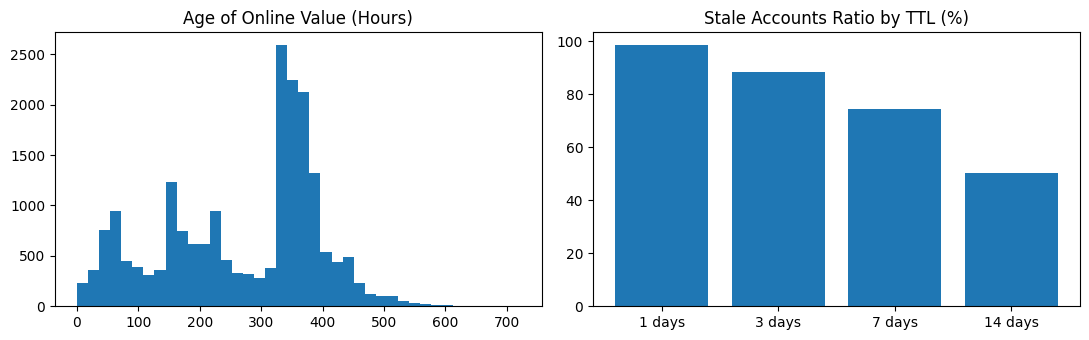

In [173]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(latest["age_hours"], bins=40)
ax[0].set_title("Age of Online Value (Hours)")

ttls = [1, 3, 7, 14]
shares = [(latest["age_hours"] > d * 24).mean() * 100 for d in ttls]
ax[1].bar([str(d) + " days" for d in ttls], shares)
ax[1].set_title("Stale Accounts Ratio by TTL (%)")
plt.tight_layout()
plt.show()

I measured the TTL selection: the median age of the accounts is 337 hours (~14 days). At TTL = 7 days, 74.6% of the accounts are considered stale, while at TTL = 14 days, 50.3% are stale. Due to data sparsity, a short TTL leaves the features empty. A shorter TTL provides fresher values, whereas a longer TTL increases coverage. While TTL = 7 days is a compromise, a longer TTL (e.g., 14–30 days) would be more logical for this dataset in terms of coverage.

---
TTL seçimini ölçdüm: hesabların median yaşı 337 saatdır (~14 gün). TTL=7 gündə hesabların 74.6%-i, TTL=14 gündə 50.3%-i köhnəlmiş sayılır. Data seyrək olduğu üçün qısa TTL feature-ləri boş buraxır. Qısa TTL daha təzə dəyər verir, uzun TTL isə əhatəni artırır. TTL=7 gün kompromis seçimidir, amma bu datada daha uzun TTL (məs. 14-30 gün) əhatə baxımından daha məntiqli olardı.

## Fraud Model

In [174]:
feat_cols = ["txn_count_24h", "transfer_count_24h", "cashout_count_24h", "avg_amount_24h"]

d = training_df.copy()
d["event_timestamp"] = d["event_timestamp"].dt.tz_localize(None)

cut = pd.Timestamp("2025-01-24")
train = d[d["event_timestamp"] < cut]
test = d[d["event_timestamp"] >= cut]

print("Train:", len(train), "Fraud:", train["isFraud"].sum())
print("Test :", len(test), "Fraud:", test["isFraud"].sum())

model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(train[feat_cols], train["isFraud"])

proba = model.predict_proba(test[feat_cols])[:, 1]
print("ROC-AUC:", round(roc_auc_score(test["isFraud"], proba), 3))
print(classification_report(test["isFraud"], model.predict(test[feat_cols])))

Train: 193312 Fraud: 6003
Test : 6625 Fraud: 2130
ROC-AUC: 0.52
              precision    recall  f1-score   support

           0       0.92      0.04      0.08      4495
           1       0.33      0.99      0.49      2130

    accuracy                           0.35      6625
   macro avg       0.62      0.52      0.29      6625
weighted avg       0.73      0.35      0.22      6625



In [175]:
sample_accounts = latest["nameDest"].head(5).tolist()

live = store.get_online_features(
    features=[f"account_features:{c}" for c in feat_cols],
    entity_rows=[{"nameDest": a} for a in sample_accounts]).to_df()

live["fraud_probability"] = model.predict_proba(live[feat_cols])[:, 1]
live

,nameDest,transfer_count_24h,txn_count_24h,cashout_count_24h,avg_amount_24h,fraud_probability
0,C788887602,0,0,0,0.000000,0.637698
1,C796621377,0,3,1,36656.582031,0.372636
2,C617009388,1,5,2,161079.531250,0.231112
3,C1086568568,0,5,2,130009.468750,0.169577
4,C1368205157,0,0,0,0.000000,0.637698


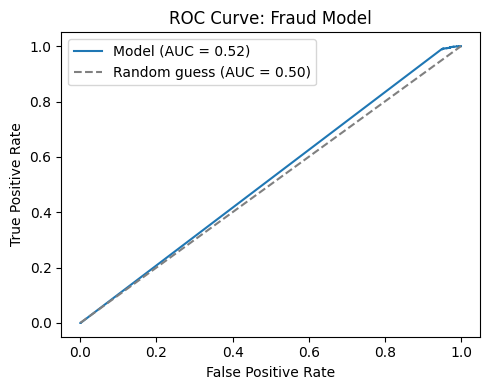

In [176]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, _ = roc_curve(test["isFraud"], proba)
auc = roc_auc_score(test["isFraud"], proba)

plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"Model (AUC = {auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess (AUC = 0.50)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Fraud Model")
plt.legend()
plt.tight_layout()
plt.show()

The model yielded a ROC-AUC of 0.52 because the features only look at the recipient account's past 24 hours and do not carry a signal that distinguishes fraud. The objective is not model quality, but rather to demonstrate that the same features work identically in both training and live lookup.

---
Model ROC-AUC 0.52 verdi, çünki feature-lər yalnız alan hesabın keçmiş 24 saatına baxır və fırıldağı ayırd edən siqnal daşımır. Məqsəd model keyfiyyəti deyil, eyni feature-lərin təlimdə və canlı lookup-da işlədiyini göstərməkdir.